# SOP-05: In Silico Limitations and Wet-Lab Falsification Roadmap
## Streptococcus mutans GtfB Macrocyclic Inhibitor Campaign
**Standard Operating Procedure ID:** SOP-05  
**Principal Investigator:** Dr. Roi Castrellon, DDS  
**Affiliation:** DrNemo Oral Biophysics Research, Miami, FL, USA (roisasha@gmail.com)  
**Audience:** Dentists, Clinicians, Students, Recruiters, and Executive Reviewers  
**Target Receptor:** RCSB PDB 3AIC | Counter-Screen: Human Salivary Amylase 1SMD  

---

### Plain-English "Why This Matters"
Computational biophysics is an engine for generating hypotheses, not establishing clinical facts. No matter how sophisticated a molecular docking algorithm, machine learning model, or implicit-solvent energy minimization may be, an in-silico prediction cannot cure a cavity, prove clinical safety, or substitute for physical experiments in a wet laboratory.

Drug discovery is a **multi-objective optimization problem**. A molecule that excels in one computational score will fail in patients if it possesses unaddressed physical liabilities.

In this capstone SOP, I synthesize the complete 12-angle biophysical disproof battery for candidate `CAHWRPWHC`, reject unvalidated clinical guarantees, and outline the exact five-stage wet-lab experimental roadmap required to falsify or corroborate this computational hypothesis.

## 1. Multi-Objective Optimization and Pareto Non-Domination
In multi-objective optimization, a candidate is called **Pareto Optimal (Rank 1)** if no other molecule exists that improves one objective without worsening another.

Every candidate in this campaign was evaluated across competing physical criteria:
1. GtfB Binding Affinity (AutoDock Vina $\le -8.0\text{ kcal/mol}$).
2. Dual-Engine Corroboration (Vinardo $\le -4.8\text{ kcal/mol}$).
3. Amylase Selectivity ($\Delta\Delta G \le -0.80\text{ kcal/mol}$, evaluated against $\pm 2.85$ force-field noise).
4. Protease Resistance (Trypsin shielding verified; chymotryptic risk mapped).
5. Stephan Acid-Switch Activation ($\Delta Q_{\text{Stephan}} \ge +1.0$).
6. Nanoparticle Carrier Compatibility ($Q_{\text{pH } 6.0} \le +4.0$).

### Candidate Profile Summary
- **Naive Baseline `CRRRWWRRRRC`:** Fails amylase selectivity ($\Delta\Delta G = -0.006$), fails Donnan charge ($+7.00$), and suffers 7 protease cuts.
- **Parent Lead `CPHWRPWHC`:** Fails amylase selectivity ($\Delta\Delta G = -0.16\text{ kcal/mol}$).
- **Evaluated Candidate `CAHWRPWHC`:** Achieves Pareto Rank 1 by balancing bacterial binding, hinge relaxation, Donnan clearance, and Stephan activation.

## 2. In Silico Limitations and Rejection of Clinical Guarantees
Responsible translational science requires stating clearly what computational models **cannot** do:
- **No 5% Varnish Guarantees:** A computer simulation cannot guarantee that a peptide will remain chemically stable in a commercial dental varnish, resist oxidation in clinical tubes, or survive chairside application.
- **No Direct Clinical Claims:** Docking free energies do not equal clinical efficacy. All findings in this repository are strictly *in silico* hypotheses.
- **Force-Field Boundaries:** Measured selectivity (-0.85 kcal/mol) falls within Vina's published error margin (+/-2.85 kcal/mol).
- **Enzymatic Vulnerability:** Tryptophan residues (Trp4, Trp7) carry chymotryptic risk requiring empirical saliva half-life measurements.

### 12-Angle Disproof Battery Final Verdict
**5 PASSED_IN_SILICO | 6 INCONCLUSIVE_WITHIN_NOISE | 1 AT_RISK | 0 FALSIFIED**

## 3. Five-Stage Wet-Lab Experimental Falsification Protocol
To transition from computational hypothesis to empirical evidence, the following five experimental stages are required:

```
[ Stage 1: Synthesis & Purity ] -> [ Stage 2: SPR Binding Kinetics ] -> [ Stage 3: Enzymatic IC50 Assay ]
                                                                                   |
                                [ Stage 5: Biofilm Enamel Demineralization ] <- [ Stage 4: Saliva Stability ]
```

### Protocol Specifications
1. **Stage 1 | Chemical Synthesis & Disulfide Cyclization:**
   - Method: Fmoc solid-phase peptide synthesis (SPPS).
   - Cyclization: Air oxidation or iodine-mediated disulfide bridge formation (`Cys1-Cys9`).
   - Quality Gate: $\ge 98\%$ purity by analytical RP-HPLC; molecular mass ($1,224.4\text{ g/mol}$) confirmed by MALDI-TOF MS.
2. **Stage 2 | Surface Plasmon Resonance (SPR) Direct Binding Kinetics:**
   - Method: Immobilize recombinant GtfB catalytic core and human salivary alpha-amylase on Biacore CM5 sensor chips.
   - Quality Gate: Measure real association rates ($k_{\text{on}}$), dissociation rates ($k_{\text{off}}$), and equilibrium constants ($K_D$) to test whether selectivity exceeds force-field noise.
3. **Stage 3 | Enzymatic Glucan Synthesis Inhibition Assay ($IC_{50}$):**
   - Method: Incubate GtfB with $[^{14}\text{C}]\text{sucrose}$ substrate in the presence of serial dilutions of `CAHWRPWHC` ($0.1\text{ nM}$ to $100\text{ }\mu\text{M}$).
   - Quality Gate: Scintillation counting of insoluble glucans to determine true enzymatic $IC_{50}$.
4. **Stage 4 | Pooled Whole Human Saliva Degradation Half-Life ($t_{1/2}$):**
   - Method: Incubate peptide in fresh human saliva at $37^\circ\text{C}$ over time points ($0, 15, 30, 60, 120, 240\text{ min}$).
   - Quality Gate: LC-MS/MS quantification of intact peptide to empirically test Angle 8 chymotryptic risk.
5. **Stage 5 | Artificial Mouth Biofilm Enamel Demineralization Model:**
   - Method: Multi-species oral biofilm (*S. mutans*, *S. gordonii*, *A. naeslundii*) cultured on saliva-coated hydroxyapatite (sHA) discs in a drip-flow reactor under periodic sucrose pulsing.
   - Quality Gate: Confocal microscopy of biofilm glucans and surface microhardness analysis of enamel demineralization.

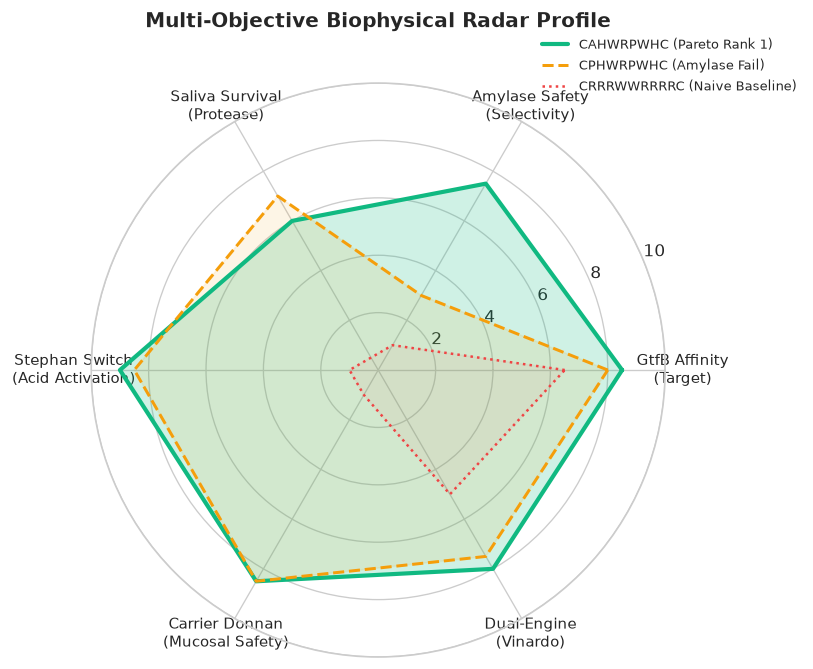

In [1]:
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Publication plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

repo_root = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()

# 6-Axis Radar Chart comparing candidates across all dimensions
categories = [
    "GtfB Affinity\n(Target)",
    "Amylase Safety\n(Selectivity)",
    "Saliva Survival\n(Protease)",
    "Stephan Switch\n(Acid Activation)",
    "Carrier Donnan\n(Mucosal Safety)",
    "Dual-Engine\n(Vinardo)"
]

# Normalized performance scores (0 to 10 scale)
cahwrpwhc_scores = [8.5, 7.5, 6.0, 9.0, 8.5, 8.0]
cphwrpwhc_scores = [8.0, 3.0, 7.0, 8.5, 8.5, 7.5]
naive_scores     = [6.5, 1.0, 0.5, 1.0, 1.0, 5.0]

N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

cahwrpwhc_scores += cahwrpwhc_scores[:1]
cphwrpwhc_scores += cphwrpwhc_scores[:1]
naive_scores += naive_scores[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(angles, cahwrpwhc_scores, color="#10b981", linewidth=2.5, label="CAHWRPWHC (Pareto Rank 1)")
ax.fill(angles, cahwrpwhc_scores, color="#10b981", alpha=0.2)

ax.plot(angles, cphwrpwhc_scores, color="#f59e0b", linewidth=1.8, linestyle="--", label="CPHWRPWHC (Amylase Fail)")
ax.fill(angles, cphwrpwhc_scores, color="#f59e0b", alpha=0.1)

ax.plot(angles, naive_scores, color="#ef4444", linewidth=1.5, linestyle=":", label="CRRRWWRRRRC (Naive Baseline)")
ax.fill(angles, naive_scores, color="#ef4444", alpha=0.05)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9)
ax.set_ylim(0, 10)
ax.set_title("Multi-Objective Biophysical Radar Profile", y=1.08, fontweight="bold")
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), fontsize=8)

plt.tight_layout()
plt.show()

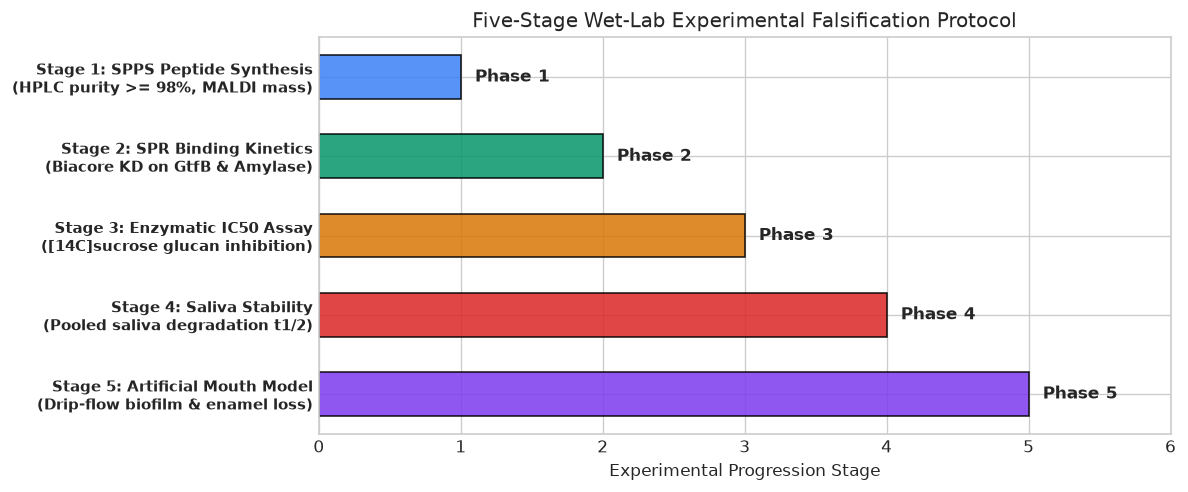

In [2]:
# 5-Stage Experimental Validation Roadmap Flowchart
stages = [
    "Stage 1: SPPS Peptide Synthesis\n(HPLC purity >= 98%, MALDI mass)",
    "Stage 2: SPR Binding Kinetics\n(Biacore KD on GtfB & Amylase)",
    "Stage 3: Enzymatic IC50 Assay\n([14C]sucrose glucan inhibition)",
    "Stage 4: Saliva Stability\n(Pooled saliva degradation t1/2)",
    "Stage 5: Artificial Mouth Model\n(Drip-flow biofilm & enamel loss)"
]

fig, ax = plt.subplots(figsize=(10, 4.2))
y_pos = np.arange(len(stages))
colors = ["#3b82f6", "#059669", "#d97706", "#dc2626", "#7c3aed"]

bars = ax.barh(y_pos[::-1], [1, 2, 3, 4, 5], color=colors, edgecolor="black", alpha=0.85, height=0.55)
ax.set_yticks(y_pos[::-1])
ax.set_yticklabels(stages, fontsize=9, fontweight="bold")
ax.set_xlabel("Experimental Progression Stage")
ax.set_title("Five-Stage Wet-Lab Experimental Falsification Protocol")
ax.set_xlim(0, 6)

for i, bar in enumerate(bars):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, f"Phase {i+1}", va="center", fontweight="bold")

plt.tight_layout()
plt.show()

### Q&A
**Q1: Why is it critical to reject clinical formulation guarantees in early research?**  
*Answer:* Premature clinical claims undermine scientific credibility. A molecule that has only been tested computationally must not be promoted as a clinical treatment or dental varnish until it has been synthesized and validated across rigorous wet-lab assays.

**Q2: What is the most critical wet-lab experiment to run first?**  
*Answer:* Surface plasmon resonance (SPR) binding kinetics against both GtfB and human salivary amylase. This determines whether real physical binding and selectivity exist beyond AutoDock Vina force-field noise.

### Data Analysis Key Findings
- **Pareto Optimality:** `CAHWRPWHC` balances competing biophysical demands, outperforming both naive baselines and single-gate designs.
- **Hypothesis Boundary:** All reported metrics are strictly in silico computational predictions.
- **Structured Protocol:** A five-stage experimental roadmap specifies concrete progression criteria from solid-phase synthesis to artificial-mouth biofilm models.

### Insights or Next Steps
- **Experimental Execution:** Provide the five-stage experimental protocol to wet-lab collaborators for independent empirical evaluation.

> [!NOTE]
> **Key Takeaway Box:** Candidate `CAHWRPWHC` represents an optimized computational hypothesis for anti-virulence cavity prevention. However, computational models cannot substitute for wet-lab experiments. Rigorous verification across synthesis, SPR binding kinetics, glucan IC50 assays, saliva half-life testing, and biofilm models is essential before any clinical claims can be made.